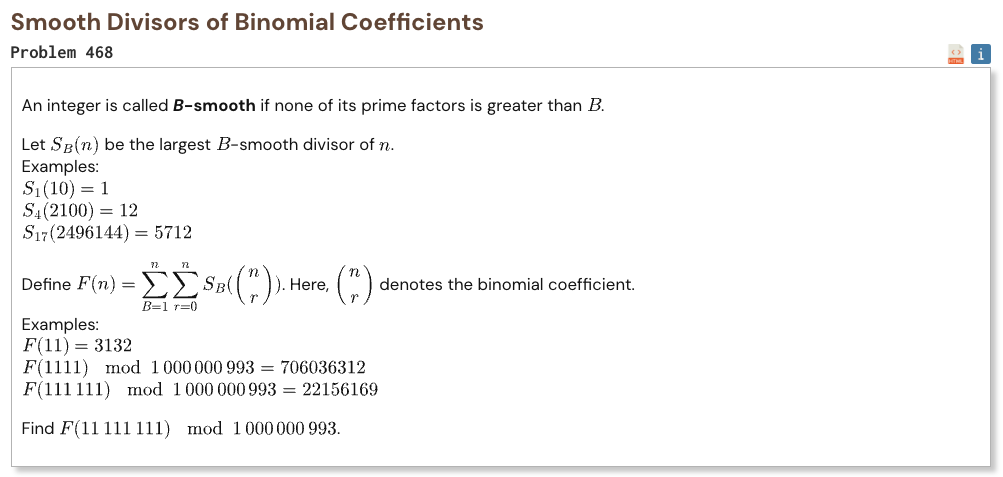

## Initial approach

- track the prime factors of each binomial coefficient as you move through the row
- update only the factors that change between neighboring coefficients
- use prime gaps to group smoothness limits that give the same value
- store the running prime products in a segment tree for fast updates
- use symmetry so only half of the binomial row needs to be processed
- keep all calculations modulo the required number

In [1]:
%%time

from array import array
from math import isqrt

N = 11_111_111
MOD = 1_000_000_993

spf = array("I", range(N + 1))

for p in range(2, isqrt(N) + 1):
    if spf[p] == p:
        start = p * p

        for x in range(start, N + 1, p):
            if spf[x] == x:
                spf[x] = p

primes = array("I")

for x in range(2, N + 1):
    if spf[x] == x:
        primes.append(x)

prime_pos = array("I", [0]) * (N + 1)

for i, p in enumerate(primes):
    prime_pos[p] = i

inverse = array("I", [0]) * (N + 1)
inverse[1] = 1

for i in range(2, N + 1):
    inverse[i] = (
        MOD
        - (MOD // i) * inverse[MOD % i] % MOD
    )

count = len(primes)

weights = array("I", [0]) * count

for i in range(count):
    if i + 1 < count:
        weights[i] = primes[i + 1] - primes[i]
    else:
        weights[i] = N + 1 - primes[i]

size = 1

while size < count:
    size *= 2

product = array("I", [1]) * (2 * size)
weighted = array("I", [0]) * (2 * size)

for i in range(count):
    weighted[size + i] = weights[i] % MOD

for node in range(size - 1, 0, -1):
    left = node * 2
    right = left + 1

    product[node] = (
        product[left] * product[right]
    ) % MOD

    weighted[node] = (
        weighted[left]
        + product[left] * weighted[right]
    ) % MOD

def update(index, factor):
    node = size + index

    product[node] = (
        product[node] * factor
    ) % MOD

    weighted[node] = (
        weighted[node] * factor
    ) % MOD

    node //= 2

    while node:
        left = node * 2
        right = left + 1

        product[node] = (
            product[left] * product[right]
        ) % MOD

        weighted[node] = (
            weighted[left]
            + product[left] * weighted[right]
        ) % MOD

        node //= 2

def apply_number(value, divide):
    while value > 1:
        p = spf[value]
        prime_power = 1

        while value % p == 0:
            value //= p
            prime_power *= p

        index = prime_pos[p]

        if divide:
            factor = inverse[prime_power]
        else:
            factor = prime_power % MOD

        update(index, factor)

result = 0
half = N // 2

for r in range(half + 1):
    contribution = (weighted[1] + 1) % MOD
    result = (result + 2 * contribution) % MOD

    if r == half:
        break

    apply_number(N - r, False)
    apply_number(r + 1, True)

print("Result:", result)

Result: 852950321
CPU times: user 2min 46s, sys: 780 ms, total: 2min 47s
Wall time: 2min 49s
